# Random Forest for IPL chase win probability

Implementing a Random Forest experiment and compare it with the Logistic Regression baseline.

Methodology decisions:
- Use the same six numeric match-state features as the deployed baseline. Do not include `match_id`, team names, or post-match information as predictors.
- Use seasons through **2024** for model development and seasons **2025–2026** as a chronological holdout. The CSV currently ends on **2026-05-01**, so the 2026 portion is partial.
- Tune `min_samples_leaf` using match-grouped cross-validation on development seasons only. Larger leaves often improve probability estimates by avoiding tiny, overconfident leaves.
- Evaluate the selected Random Forest and Logistic Regression on exactly the same chronological holdout.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
_ip = get_ipython()
if _ip is not None:
    _ip.run_line_magic("matplotlib", "inline")

from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [3]:
# Support both common VS Code notebook working directories: repo root or models/.
DATA_CANDIDATES = [
    Path("data/processed/reduced/Final_data.csv"),
    Path("../data/processed/reduced/Final_data.csv"),
]
DATA_PATH = next((p.resolve() for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Cannot find data/processed/reduced/Final_data.csv. "
        "Open the repository folder in VS Code and check the dataset is present."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded dataset: {DATA_PATH.name}")
print(f"Rows: {len(df):,} | Matches: {df['match_id'].nunique():,}")
print(f"Seasons: {df['season_id'].min()}–{df['season_id'].max()}")
df.head()

Loaded dataset: Final_data.csv
Rows: 117,558 | Matches: 1,063
Seasons: 2008–2026


,match_id,team_batting,team_bowling,current_score,season_id,match_date,city,venue,target_runs,runs_left,CRR,balls_left,RRR,wickets_left,runs_last_30,wickets_last_30,won
0,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,1,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,222,6.0,119,11.193277,10,1.0,0.0,0
1,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,2,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,221,6.0,118,11.237288,10,2.0,0.0,0
2,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,3,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,220,6.0,117,11.282051,10,3.0,0.0,0
3,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,4,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,219,6.0,116,11.327586,10,4.0,0.0,0
4,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,4,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,219,4.8,115,11.426087,10,4.0,0.0,0


## 1. Define the prediction inputs and the temporal holdout

`match_id` is used only to group rows, never as a feature. We check that a match has one final outcome label and that there are no missing values in the columns used by this experiment.

Why split by season? A live predictor will be used on future matches. A random match split can still mix older and newer seasons between train and test, masking changes in teams, playing conditions, and scoring patterns.

In [4]:
FEATURES = [
    "target_runs",
    "runs_left",
    "CRR",
    "balls_left",
    "RRR",
    "wickets_left",
]
TARGET = "won"
GROUP = "match_id"

required = FEATURES + [TARGET, GROUP, "season_id"]
assert df[required].notna().all().all(), "Missing values found in required modelling columns."
assert not (df.groupby(GROUP)[TARGET].nunique() > 1).any(), "A match has inconsistent outcome labels."

# Historical development data vs. newer seasons held out from model fitting/tuning.
dev = df.loc[df["season_id"] <= 2024].copy().reset_index(drop=True)
temporal_test = df.loc[df["season_id"] >= 2025].copy().reset_index(drop=True)
assert set(dev[GROUP]).isdisjoint(set(temporal_test[GROUP]))

X_dev, y_dev, groups_dev = dev[FEATURES], dev[TARGET].astype(int), dev[GROUP]
X_test, y_test = temporal_test[FEATURES], temporal_test[TARGET].astype(int)

print(f"Development: {len(dev):,} delivery states | {groups_dev.nunique():,} matches | seasons {dev.season_id.min()}–{dev.season_id.max()}")
print(f"Temporal holdout: {len(temporal_test):,} delivery states | {temporal_test[GROUP].nunique():,} matches | seasons {temporal_test.season_id.min()}–{temporal_test.season_id.max()}")
print("Holdout latest date:", temporal_test["match_date"].max())
print("Target distribution in development:\n", y_dev.value_counts(normalize=True).round(3).to_dict())
print("Target distribution in holdout:\n", y_test.value_counts(normalize=True).round(3).to_dict())

Development: 105,663 delivery states | 953 matches | seasons 2008–2024
Temporal holdout: 11,895 delivery states | 110 matches | seasons 2025–2026
Holdout latest date: 2026-05-01
Target distribution in development:
 {1: 0.513, 0: 0.487}
Target distribution in holdout:
 {1: 0.54, 0: 0.46}


## 2. Tune one Random Forest hyperparameter with grouped CV

`min_samples_leaf` controls the minimum number of training rows in a leaf. Very small leaves can memorize individual delivery states and produce extreme probabilities. We compare four predeclared settings on the development seasons using the same three match-grouped folds. We choose the setting with the lowest **mean validation log loss**, because the app needs useful probabilities, not only 0/1 labels.

This is a small, interpretable search—not an exhaustive hyperparameter optimization.

In [5]:
LEAF_OPTIONS = [20, 50, 100, 150]
N_SPLITS = 3
N_TREES_FOR_TUNING = 80
cv = GroupKFold(n_splits=N_SPLITS)
cv_rows = []

for leaf_size in LEAF_OPTIONS:
    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_dev, y_dev, groups_dev), start=1
    ):
        train_groups = set(groups_dev.iloc[train_idx])
        val_groups = set(groups_dev.iloc[val_idx])
        assert train_groups.isdisjoint(val_groups), "Match leakage across CV fold."

        rf = RandomForestClassifier(
            n_estimators=N_TREES_FOR_TUNING,
            min_samples_leaf=leaf_size,
            max_features="sqrt",
            n_jobs=-1,
            random_state=42,
        )
        rf.fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
        p_val = rf.predict_proba(X_dev.iloc[val_idx])[:, 1]
        y_val = y_dev.iloc[val_idx]

        cv_rows.append({
            "min_samples_leaf": leaf_size,
            "fold": fold,
            "log_loss": log_loss(y_val, p_val),
            "brier": brier_score_loss(y_val, p_val),
            "roc_auc": roc_auc_score(y_val, p_val),
            "accuracy": accuracy_score(y_val, p_val >= 0.5),
        })

cv_results = pd.DataFrame(cv_rows)
cv_summary = (
    cv_results.groupby("min_samples_leaf")
    .agg(
        log_loss_mean=("log_loss", "mean"),
        log_loss_std=("log_loss", "std"),
        brier_mean=("brier", "mean"),
        roc_auc_mean=("roc_auc", "mean"),
        accuracy_mean=("accuracy", "mean"),
    )
    .sort_values("log_loss_mean")
)
display(cv_summary.round(4))
best_leaf_size = int(cv_summary.index[0])
print(f"Selected min_samples_leaf={best_leaf_size} by development CV log loss.")

,log_loss_mean,log_loss_std,brier_mean,roc_auc_mean,accuracy_mean
min_samples_leaf,,,,,
150,0.4556,0.0254,0.1503,0.8658,0.7764
100,0.4581,0.0290,0.1511,0.8646,0.7754
50,0.4668,0.0362,0.1538,0.8602,0.7712
20,0.4970,0.0395,0.1589,0.8531,0.7636


Selected min_samples_leaf=150 by development CV log loss.


## 3. Fit the selected Random Forest and the baseline

The temporal holdout has not been used to select the leaf size above. We now fit both candidate models on all development seasons and evaluate them on the same newer-season holdout. The Logistic Regression baseline uses scaling inside its pipeline; Random Forest does not need feature scaling.

In [6]:
rf_final = RandomForestClassifier(
    n_estimators=N_TREES_FOR_TUNING,
    min_samples_leaf=best_leaf_size,
    max_features="sqrt",
    n_jobs=-1,
    random_state=42,
)
rf_final.fit(X_dev, y_dev)
p_rf = rf_final.predict_proba(X_test)[:, 1]

logreg = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000)),
])
logreg.fit(X_dev, y_dev)
p_lr = logreg.predict_proba(X_test)[:, 1]

def probability_report(name, y_true, probabilities):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, probabilities >= 0.5),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "log_loss": log_loss(y_true, probabilities),
        "brier": brier_score_loss(y_true, probabilities),
    }

temporal_results = pd.DataFrame([
    probability_report("Logistic Regression", y_test, p_lr),
    probability_report("Random Forest", y_test, p_rf),
]).set_index("model")
display(temporal_results.sort_values("log_loss").round(4))

,accuracy,roc_auc,log_loss,brier
model,,,,
Logistic Regression,0.7935,0.9001,0.4244,0.1391
Random Forest,0.7843,0.8886,0.4523,0.1486


## 4. Check probability calibration

A model may rank outcomes well and still give probabilities that are too confident. In a reliability plot, predicted probability is on the x-axis and the observed win frequency is on the y-axis. A well-calibrated model should be near the diagonal. This plot uses the temporal holdout, so do not repeatedly tune the model based on it.

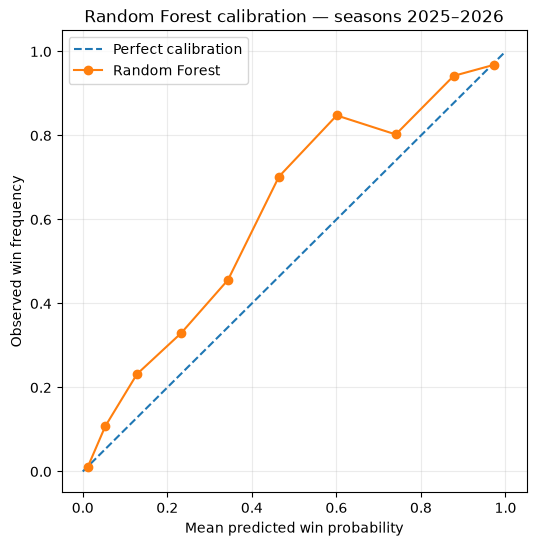

In [7]:
prob_true, prob_pred = calibration_curve(
    y_test, p_rf, n_bins=10, strategy="quantile"
)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "--", label="Perfect calibration")
ax.plot(prob_pred, prob_true, marker="o", label="Random Forest")
ax.set(xlabel="Mean predicted win probability",
       ylabel="Observed win frequency",
       title="Random Forest calibration — seasons 2025–2026")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 5. Inspect feature importance

Random Forest impurity-based importance is a diagnostic, not a causal explanation. Correlated features such as `runs_left`, `RRR`, and `balls_left` can share or distort importance. Treat this as a first look; permutation importance on the temporal holdout would be a stronger follow-up.

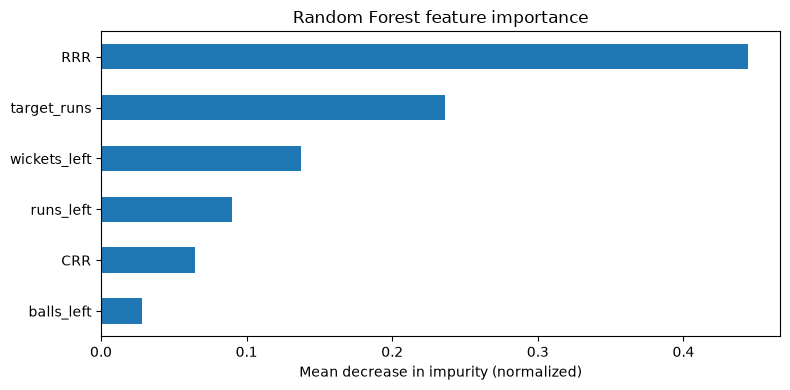

,importance
RRR,0.4441
target_runs,0.2360
wickets_left,0.1373
runs_left,0.0899
CRR,0.0644
balls_left,0.0282


In [8]:
importance = (
    pd.Series(rf_final.feature_importances_, index=FEATURES, name="importance")
    .sort_values()
)
ax = importance.plot(kind="barh", figsize=(8, 4), title="Random Forest feature importance")
ax.set_xlabel("Mean decrease in impurity (normalized)")
plt.tight_layout()
plt.show()
display(importance.sort_values(ascending=False).to_frame().round(4))

## Interpretation checklist

- Compare **log loss** and **Brier score** first when the goal is win probability; lower is better.
- Higher ROC-AUC means better ranking, not necessarily better-calibrated probabilities.
- Accuracy depends on the 0.5 threshold and is not enough to select the model.

## 6. Export reproducible score tables

These CSVs record the leaf-size search, the holdout comparison, and the feature-importance ranking. They contain scores only, not the dataset or model artifact.

In [9]:
PROJECT_ROOT_CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    (p.resolve() for p in PROJECT_ROOT_CANDIDATES if (p / ".git").exists()),
    Path.cwd().resolve(),
)
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
cv_results.to_csv(REPORT_DIR / "random_forest_tuning_folds.csv", index=False)
cv_summary.to_csv(REPORT_DIR / "random_forest_tuning_summary.csv")
temporal_results.to_csv(REPORT_DIR / "random_forest_temporal_holdout.csv")
importance.to_frame().to_csv(REPORT_DIR / "random_forest_feature_importance.csv")
print("Saved Random Forest score tables under reports/.")

Saved Random Forest score tables under reports/.
